<a href="https://colab.research.google.com/github/rajnandini241013006182-web/Rajnandini6182-AI-ML-Lab/blob/main/LAB_4_AI_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q imbalanced-learn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
uploaded = files.upload()

# Dynamically get the correct filename from the uploaded dict
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print(f"Dataset Loaded Successfully from '{filename}'!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Saving stroke_processed_5k (3).csv to stroke_processed_5k (3) (2).csv
Dataset Loaded Successfully from 'stroke_processed_5k (3) (2).csv'!

Dataset Shape:
(5110, 11)

First Five Rows:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
None

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_

Stroke Class Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Class Distribution Percentage:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


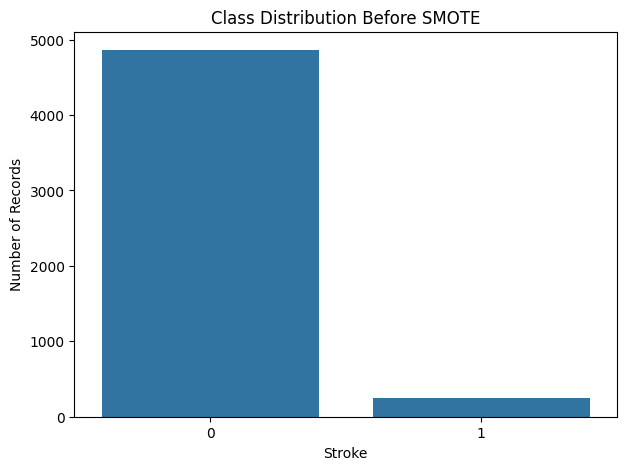

In [8]:
print("Stroke Class Distribution:")
print(df['stroke'].value_counts())

print("\nClass Distribution Percentage:")
print(df['stroke'].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='stroke'
)

plt.title("Class Distribution Before SMOTE")
plt.xlabel("Stroke")
plt.ylabel("Number of Records")

plt.show()

In [9]:
X = df.drop('stroke', axis=1)

y = df['stroke']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5110, 10)
Target Shape: (5110,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4088, 10)
Testing Data: (1022, 10)


In [11]:
categorical_features = [
    'gender',
    'hypertension',
    'heart_disease',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

smote = SMOTENC(
    categorical_features=categorical_features,
    random_state=42,
    k_neighbors=5
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced Dataset Shape:")
print(X_train_balanced.shape)

Before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64

After SMOTE:
stroke
0    3889
1    3889
Name: count, dtype: int64

Balanced Dataset Shape:
(7778, 10)


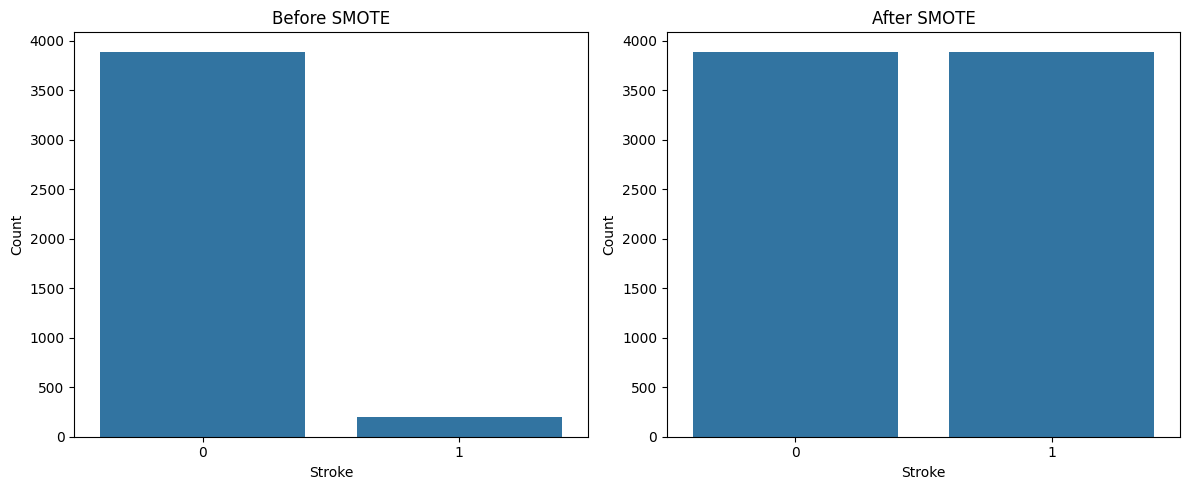

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Stroke")
axes[0].set_ylabel("Count")

sns.countplot(
    x=y_train_balanced,
    ax=axes[1]
)

axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Stroke")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42,
        early_stopping=True
    )
}

print("Six Classification Models Created Successfully!")

Six Classification Models Created Successfully!


In [14]:
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    return {
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Accuracy": accuracy,
        "AUC-ROC": auc
    }

In [15]:
original_results = {}

original_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

    pipeline.fit(X_train, y_train)

    original_models[name] = pipeline

    scores = evaluate_model(
        pipeline,
        X_test,
        y_test
    )

    original_results[name] = scores

    print("\nModel:", name)
    print(scores)

original_df = pd.DataFrame(
    original_results
).T

print("\nOriginal Dataset Results:")
display(original_df.round(4))


Model: Logistic Regression
{'Precision': 0.0, 'Recall': 0.0, 'F1-Score': 0.0, 'Accuracy': 0.9510763209393346, 'AUC-ROC': np.float64(0.8376954732510288)}

Model: Decision Tree
{'Precision': 0.16666666666666666, 'Recall': 0.18, 'F1-Score': 0.17307692307692307, 'Accuracy': 0.9158512720156555, 'AUC-ROC': np.float64(0.5668518518518518)}

Model: Random Forest
{'Precision': 0.16666666666666666, 'Recall': 0.02, 'F1-Score': 0.03571428571428571, 'Accuracy': 0.9471624266144814, 'AUC-ROC': np.float64(0.8160493827160493)}

Model: KNN
{'Precision': 0.2, 'Recall': 0.02, 'F1-Score': 0.03636363636363636, 'Accuracy': 0.9481409001956947, 'AUC-ROC': np.float64(0.6139609053497942)}

Model: SVM
{'Precision': 0.0, 'Recall': 0.0, 'F1-Score': 0.0, 'Accuracy': 0.9510763209393346, 'AUC-ROC': np.float64(0.6108230452674897)}

Model: ANN
{'Precision': 0.0, 'Recall': 0.0, 'F1-Score': 0.0, 'Accuracy': 0.9510763209393346, 'AUC-ROC': np.float64(0.3690329218106996)}

Original Dataset Results:


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.0000,0.00,0.0000,0.9511,0.8377
Decision Tree,0.1667,0.18,0.1731,0.9159,0.5669
Random Forest,0.1667,0.02,0.0357,0.9472,0.8160
KNN,0.2000,0.02,0.0364,0.9481,0.6140
SVM,0.0000,0.00,0.0000,0.9511,0.6108
ANN,0.0000,0.00,0.0000,0.9511,0.3690


In [16]:
balanced_results = {}

balanced_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

    pipeline.fit(
        X_train_balanced,
        y_train_balanced
    )

    balanced_models[name] = pipeline

    scores = evaluate_model(
        pipeline,
        X_test,
        y_test
    )

    balanced_results[name] = scores

    print("\nModel:", name)
    print(scores)

balanced_df = pd.DataFrame(
    balanced_results
).T

print("\nSMOTE Balanced Dataset Results:")
display(balanced_df.round(4))


Model: Logistic Regression
{'Precision': 0.13261648745519714, 'Recall': 0.74, 'F1-Score': 0.22492401215805471, 'Accuracy': 0.7504892367906066, 'AUC-ROC': np.float64(0.8244650205761317)}

Model: Decision Tree
{'Precision': 0.05555555555555555, 'Recall': 0.1, 'F1-Score': 0.07142857142857142, 'Accuracy': 0.87279843444227, 'AUC-ROC': np.float64(0.5062757201646091)}

Model: Random Forest
{'Precision': 0.12658227848101267, 'Recall': 0.2, 'F1-Score': 0.15503875968992248, 'Accuracy': 0.8933463796477495, 'AUC-ROC': np.float64(0.7882921810699589)}

Model: KNN
{'Precision': 0.12195121951219512, 'Recall': 0.4, 'F1-Score': 0.18691588785046728, 'Accuracy': 0.8297455968688845, 'AUC-ROC': np.float64(0.6374588477366255)}

Model: SVM
{'Precision': 0.11442786069651742, 'Recall': 0.46, 'F1-Score': 0.18326693227091634, 'Accuracy': 0.799412915851272, 'AUC-ROC': np.float64(0.7319135802469136)}

Model: ANN
{'Precision': 0.11594202898550725, 'Recall': 0.32, 'F1-Score': 0.1702127659574468, 'Accuracy': 0.847358

,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.1326,0.74,0.2249,0.7505,0.8245
Decision Tree,0.0556,0.10,0.0714,0.8728,0.5063
Random Forest,0.1266,0.20,0.1550,0.8933,0.7883
KNN,0.1220,0.40,0.1869,0.8297,0.6375
SVM,0.1144,0.46,0.1833,0.7994,0.7319
ANN,0.1159,0.32,0.1702,0.8474,0.7235


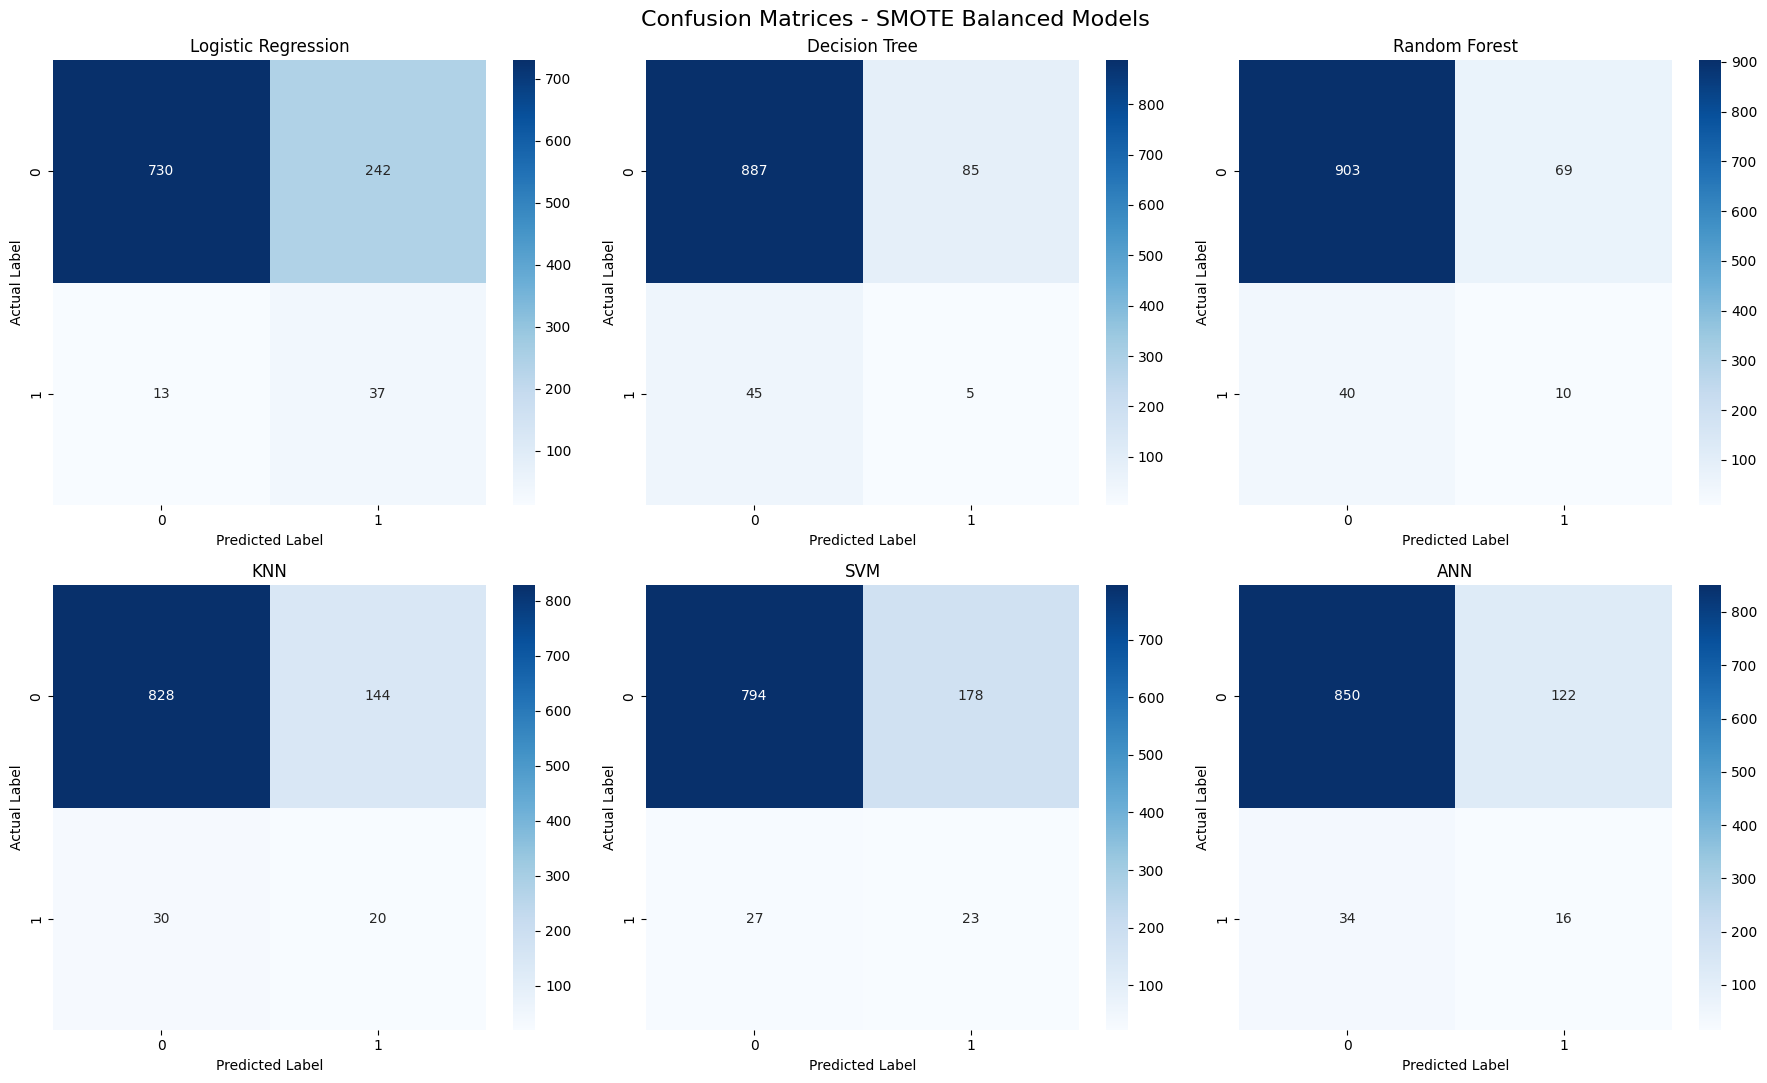

In [17]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for i, (name, model) in enumerate(balanced_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices - SMOTE Balanced Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

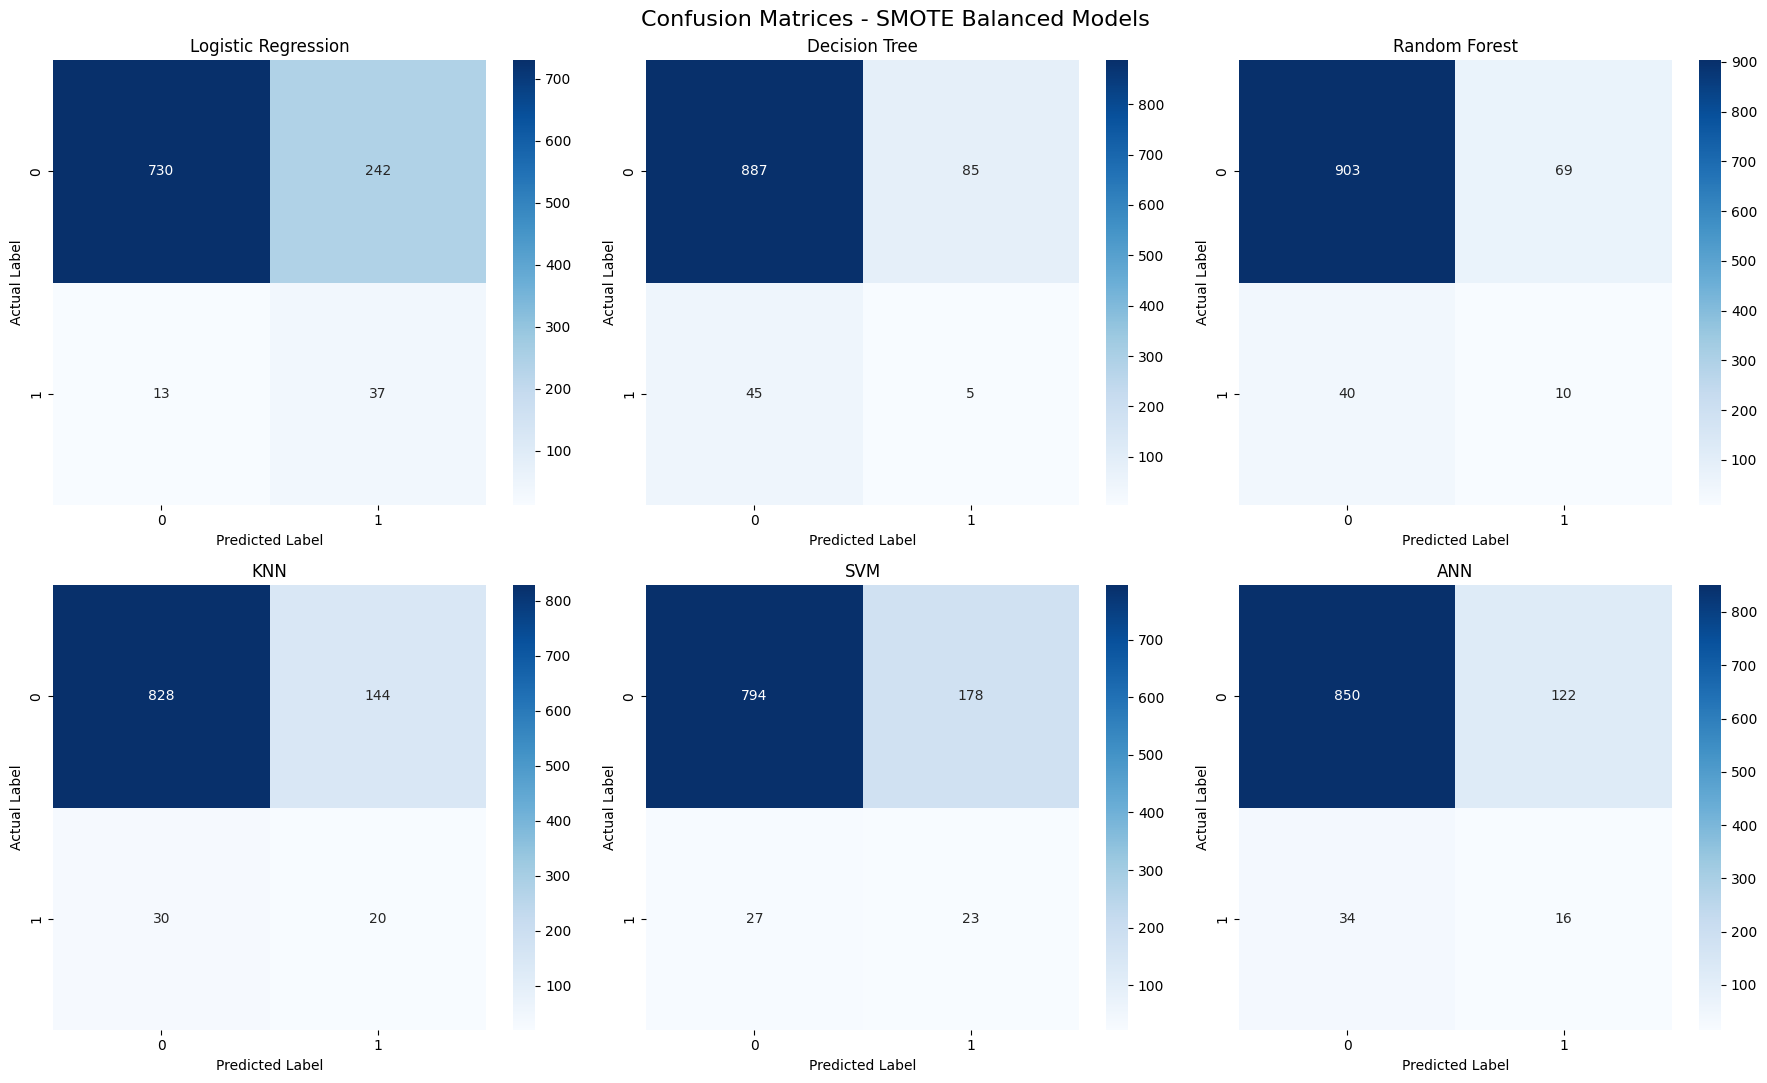

In [18]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for i, (name, model) in enumerate(balanced_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices - SMOTE Balanced Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [19]:
comparison = []

for name in models.keys():

    row = {"Model": name}

    for metric in [
        "Precision",
        "Recall",
        "F1-Score",
        "Accuracy",
        "AUC-ROC"
    ]:

        row[metric + "_Original"] = (
            original_results[name][metric]
        )

        row[metric + "_SMOTE"] = (
            balanced_results[name][metric]
        )

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

print("Original vs SMOTE Balanced Dataset Comparison:")

display(comparison_df.round(4))

Original vs SMOTE Balanced Dataset Comparison:


,Model,Precision_Original,Precision_SMOTE,Recall_Original,Recall_SMOTE,F1-Score_Original,F1-Score_SMOTE,Accuracy_Original,Accuracy_SMOTE,AUC-ROC_Original,AUC-ROC_SMOTE
0,Logistic Regression,0.0000,0.1326,0.00,0.74,0.0000,0.2249,0.9511,0.7505,0.8377,0.8245
1,Decision Tree,0.1667,0.0556,0.18,0.10,0.1731,0.0714,0.9159,0.8728,0.5669,0.5063
2,Random Forest,0.1667,0.1266,0.02,0.20,0.0357,0.1550,0.9472,0.8933,0.8160,0.7883
3,KNN,0.2000,0.1220,0.02,0.40,0.0364,0.1869,0.9481,0.8297,0.6140,0.6375
4,SVM,0.0000,0.1144,0.00,0.46,0.0000,0.1833,0.9511,0.7994,0.6108,0.7319
5,ANN,0.0000,0.1159,0.00,0.32,0.0000,0.1702,0.9511,0.8474,0.3690,0.7235


In [20]:
top_three = balanced_df.sort_values(
    by=['F1-Score', 'AUC-ROC'],
    ascending=False
).head(3)

print("TOP THREE PERFORMING MODELS")
print("Based on SMOTE Balanced Dataset")

display(top_three.round(4))

TOP THREE PERFORMING MODELS
Based on SMOTE Balanced Dataset


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.1326,0.74,0.2249,0.7505,0.8245
KNN,0.1220,0.40,0.1869,0.8297,0.6375
SVM,0.1144,0.46,0.1833,0.7994,0.7319


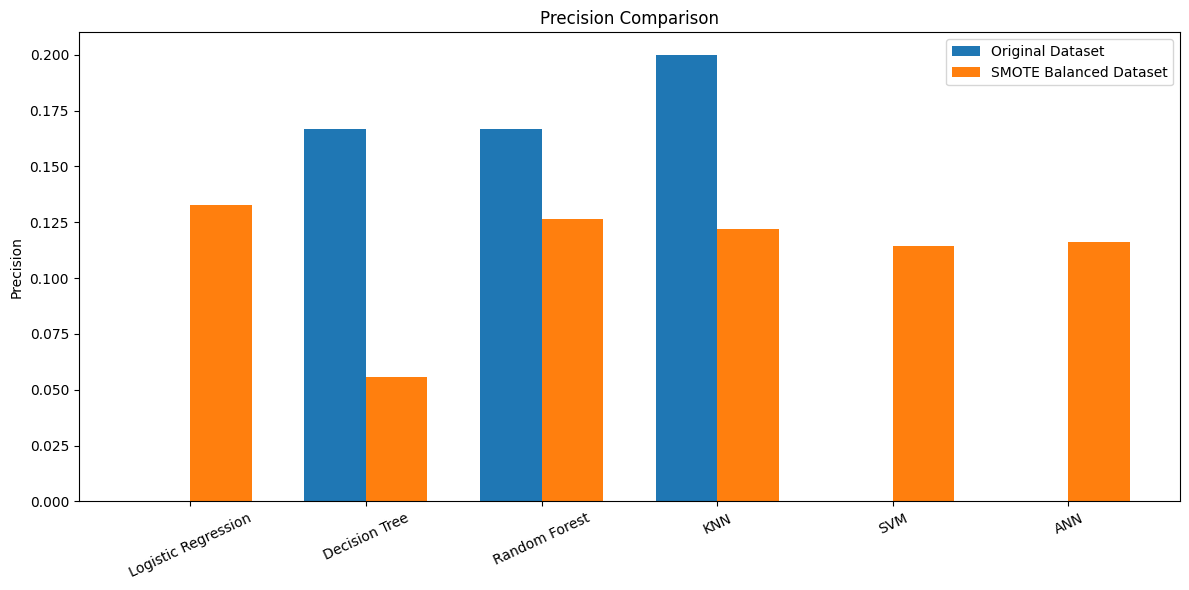

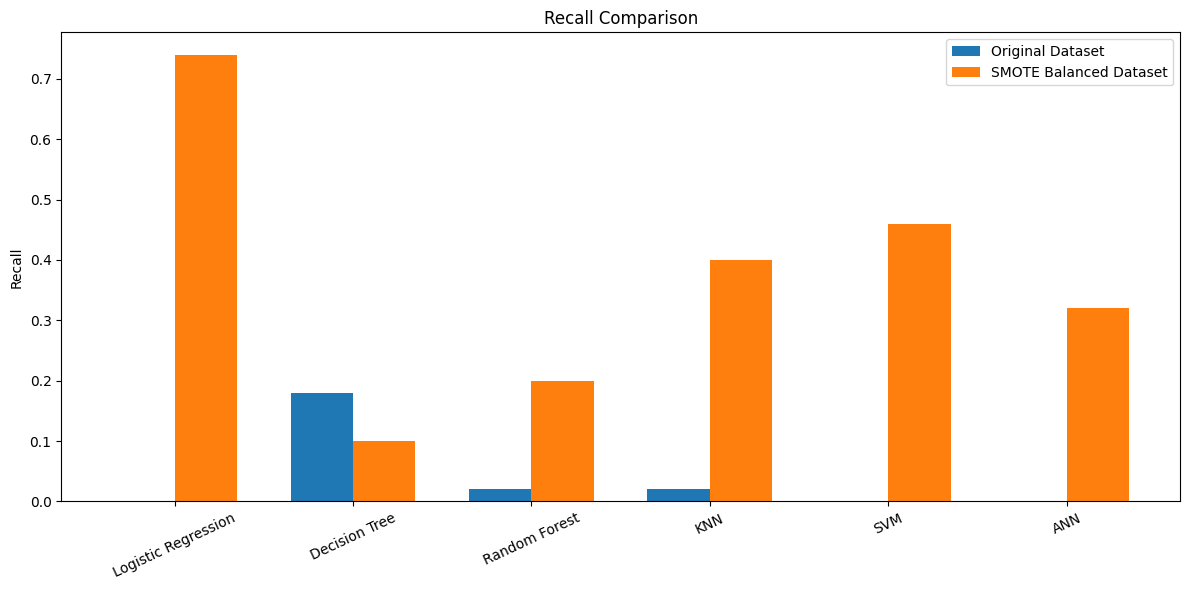

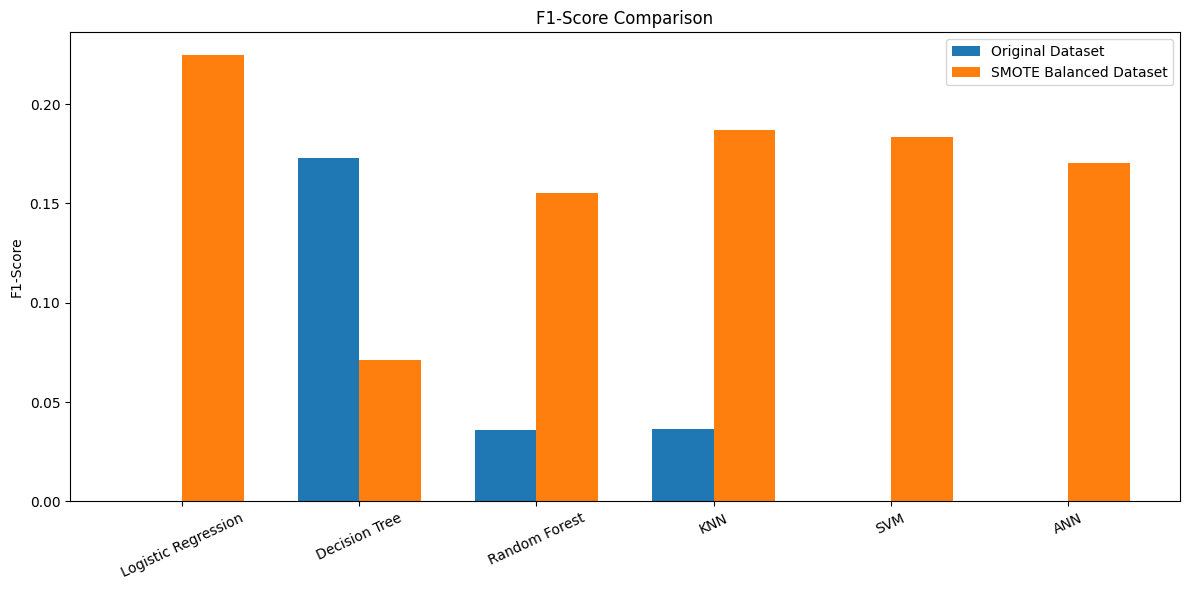

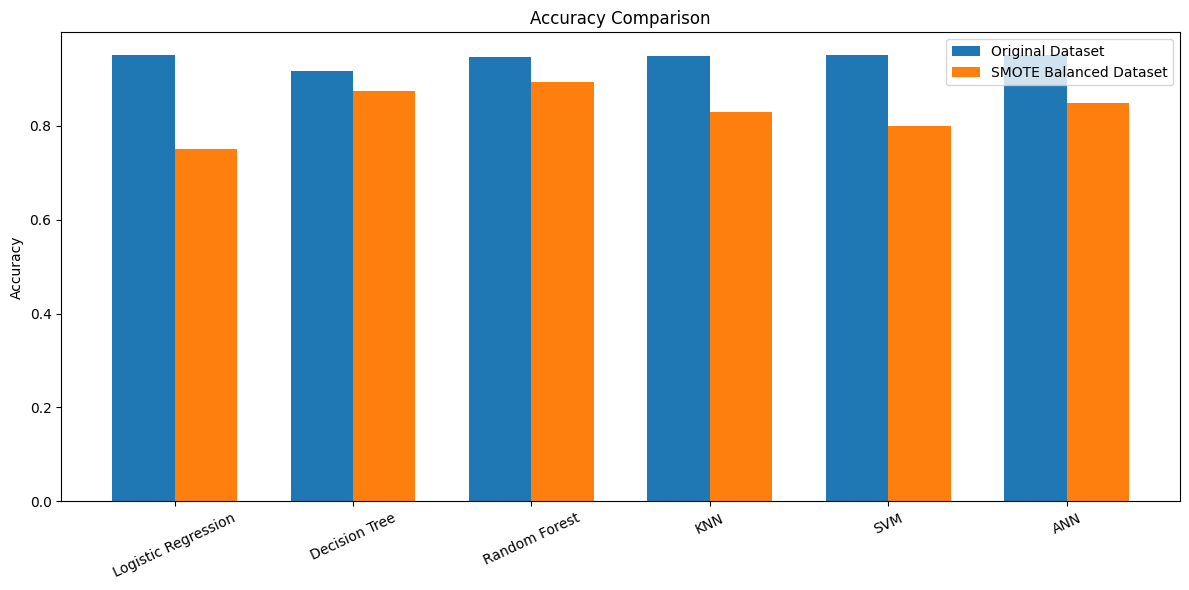

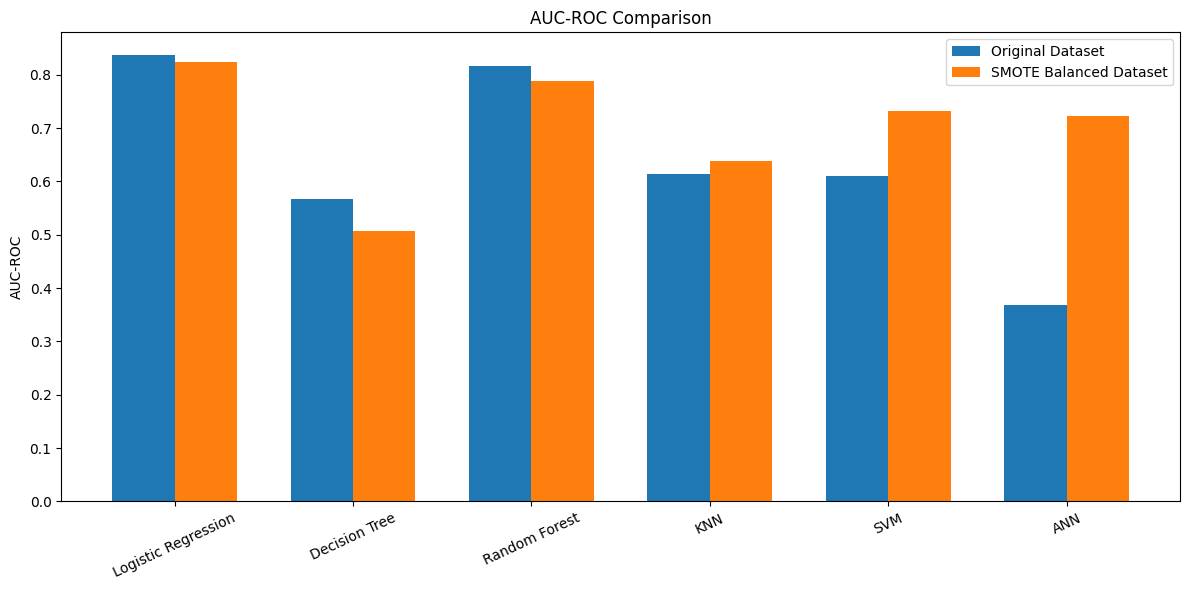

In [21]:
metrics = [
    'Precision',
    'Recall',
    'F1-Score',
    'Accuracy',
    'AUC-ROC'
]

for metric in metrics:

    plt.figure(figsize=(12, 6))

    x = np.arange(len(models))
    width = 0.35

    plt.bar(
        x - width/2,
        original_df[metric],
        width,
        label='Original Dataset'
    )

    plt.bar(
        x + width/2,
        balanced_df[metric],
        width,
        label='SMOTE Balanced Dataset'
    )

    plt.xticks(
        x,
        models.keys(),
        rotation=25
    )

    plt.ylabel(metric)
    plt.title(metric + " Comparison")

    plt.legend()
    plt.tight_layout()

    plt.show()

In [22]:
comparison_df.to_csv(
    'stroke_model_comparison.csv',
    index=False
)

top_three.to_csv(
    'top_three_models.csv'
)

original_df.to_csv(
    'original_dataset_results.csv'
)

balanced_df.to_csv(
    'smote_balanced_results.csv'
)

print("All result files saved successfully!")

All result files saved successfully!


In [23]:
files.download('stroke_model_comparison.csv')

files.download('top_three_models.csv')

files.download('original_dataset_results.csv')

files.download('smote_balanced_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>